In [1]:
import pandas as pd
from azure.ai.ml import MLClient
from azure.identity import DefaultAzureCredential

ml_client = MLClient.from_config(
    DefaultAzureCredential(),
)

data_asset = ml_client.data.get(name='housing_csv', version='1')
df = pd.read_csv(data_asset.path)

Found the config file in: ./config.json
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/mlflow/__init__.py:41: UserWarning: Versions of mlflow (3.17.1) and child packages mlflow-skinny (3.15.0) are different. This may lead to unexpected behavior. Please install the same version of all MLflow packages.
  mlflow.mismatch._check_version_mismatch()
/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  f

In [2]:
df.shape #no. of (rows, columns)

(20640, 10)

In [4]:
df.isna().sum() #check for null values

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [5]:
df_clean = df.dropna() #drop all null values and assign the clean dataset to df_clean

In [6]:
df_clean.isna().sum() #confirmation there are no more null values

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [9]:
df_clean["ocean_proximity"].value_counts() #checks the frequency of each entry

<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
Name: ocean_proximity, dtype: int64

In [8]:
df_clean = df_clean[df_clean["ocean_proximity"] != "ISLAND"] #remove all rows with ISLAND (back to prev.)

In [10]:
df_clean["median_house_value"].describe()

count     20428.000000
mean     206821.928432
std      115412.337452
min       14999.000000
25%      119475.000000
50%      179700.000000
75%      264700.000000
max      500001.000000
Name: median_house_value, dtype: float64

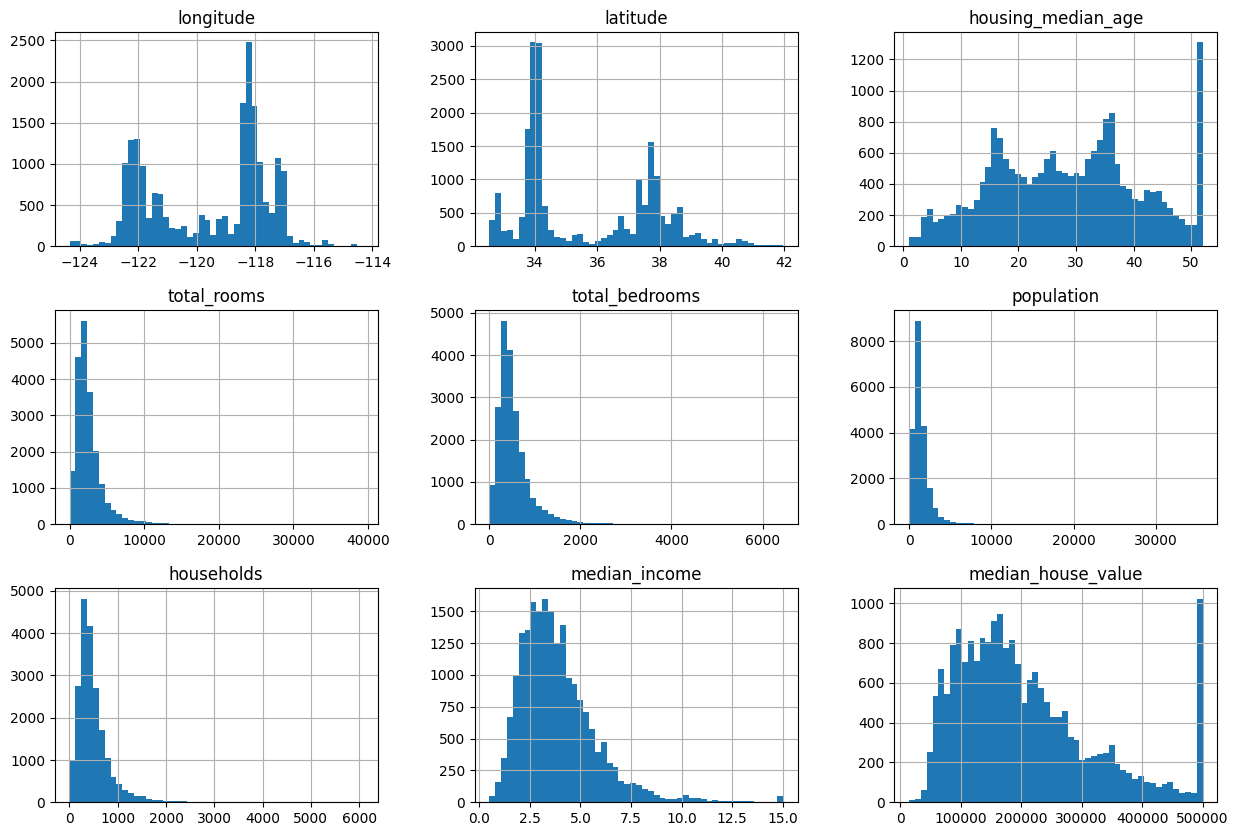

In [11]:
import matplotlib.pyplot as plt

df_clean.hist(bins=50, figsize=(15,10))
plt.show()

In [12]:
df_clean = df_clean[df_clean["median_house_value"] < 500001].copy() #dropping every value above 500000 as that shows as the max

In [13]:
df_clean.skew()

/tmp/ipykernel_4316/2859413869.py:1: FutureWarning: The default value of numeric_only in DataFrame.skew is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df_clean.skew()


longitude            -0.288594
latitude              0.454900
housing_median_age    0.070904
total_rooms           4.239187
total_bedrooms        3.457544
population            4.986304
households            3.411488
median_income         0.910386
median_house_value    0.810249
dtype: float64

In [14]:
import numpy as np

df_clean['log_median_house_value'] = np.log1p(df_clean['median_house_value'])

In [17]:
df_clean.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,log_median_house_value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,13.022766
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,12.789687
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,12.771673
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,12.740520
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,12.743154
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY,12.505069
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY,12.608871
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY,12.394215
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY,12.331387
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY,12.472663


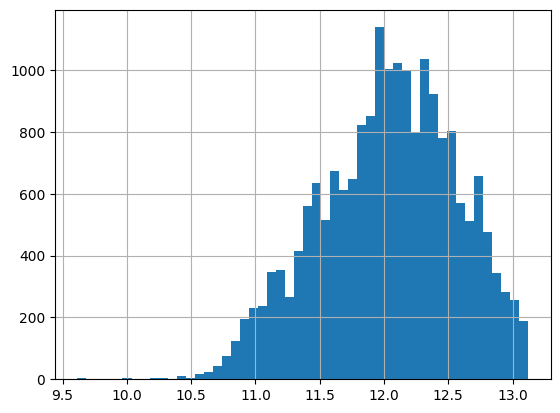

In [19]:
df_clean["log_median_house_value"].hist(bins=50)
plt.show()

In [21]:
df_clean.skew() #now includes the normalized column

/tmp/ipykernel_4316/2859413869.py:1: FutureWarning: The default value of numeric_only in DataFrame.skew is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df_clean.skew()


longitude                -0.288594
latitude                  0.454900
housing_median_age        0.070904
total_rooms               4.239187
total_bedrooms            3.457544
population                4.986304
households                3.411488
median_income             0.910386
median_house_value        0.810249
log_median_house_value   -0.294543
dtype: float64

In [23]:
df_clean["rooms/household"] = df_clean["total_rooms"]/df_clean["households"]
df_clean["bedrooms/household"] = df_clean["total_bedrooms"]/df_clean["households"]
df_clean["population/household"] = df_clean["population"]/df_clean["households"]
df_clean["bedrooms/rooms"] = df_clean["total_bedrooms"]/df_clean["rooms"]

In [25]:
df_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,log_median_house_value,rooms/household,bedrooms/household,population/household,bedrooms/rooms
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,13.022766,6.984127,1.023810,2.555556,6.984127
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,12.789687,6.238137,0.971880,2.109842,6.238137
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,12.771673,8.288136,1.073446,2.802260,8.288136
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,12.740520,5.817352,1.073059,2.547945,5.817352
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,12.743154,6.281853,1.081081,2.181467,6.281853


In [26]:
df_clean.skew()

/tmp/ipykernel_4316/2859413869.py:1: FutureWarning: The default value of numeric_only in DataFrame.skew is deprecated. In a future version, it will default to False. In addition, specifying 'numeric_only=None' is deprecated. Select only valid columns or specify the value of numeric_only to silence this warning.
  df_clean.skew()


longitude                 -0.288594
latitude                   0.454900
housing_median_age         0.070904
total_rooms                4.239187
total_bedrooms             3.457544
population                 4.986304
households                 3.411488
median_income              0.910386
median_house_value         0.810249
log_median_house_value    -0.294543
rooms/household           16.598432
bedrooms/household        29.657367
population/household      94.983114
bedrooms/rooms            16.598432
dtype: float64

In [1]:
df_clean.describe()

NameError: name 'df_clean' is not defined